# Connecting Python to SQL (SQLAlchemy & pandas)

Data pipelines and applications talk to databases from Python. This lesson covers the safe and efficient ways to do it: engines and connections, transactions, parameterised queries, pandas integration, an ORM, and fast bulk loading.

**After this lesson you can:**

1. Use SQLAlchemy engines, connections and transactions.
2. Prevent SQL injection with parameterised queries.
3. Move data between pandas and PostgreSQL (`read_sql`, `to_sql`, chunks).
4. Map tables to Python classes with the SQLAlchemy ORM.
5. Load large data quickly with PostgreSQL `COPY`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Engine, Connection, Transaction

| Object | Role |
| :--- | :--- |
| **engine** | knows how to connect; keeps a **connection pool** |
| **connection** | one open session with the database |
| **transaction** | a group of statements that succeed or fail together (Lesson 11) |

`with engine.begin() as conn:` opens a connection and a transaction; it **commits** at the end of the block, or **rolls back** if an exception occurs.

In [2]:
run("DROP TABLE IF EXISTS payments; CREATE TABLE payments (id serial PRIMARY KEY, customer text, amount numeric(10,2))")
try:
    with lab.begin() as conn:
        conn.execute(text("INSERT INTO payments (customer, amount) VALUES ('ayse', 50)"))
        conn.execute(text("INSERT INTO payments (customer, amount) VALUES ('mert', 'not a number')"))   # fails
except Exception as err:
    print("transaction rolled back:", type(err.orig).__name__)
print("rows after the failed transaction:", lq("SELECT count(*) AS n FROM payments")["n"][0])
print("connection pool:", lab.pool.status())

transaction rolled back: InvalidTextRepresentation
rows after the failed transaction: 0
connection pool: Pool size: 5  Connections in pool: 1 Current Overflow: -4 Current Checked out connections: 0


Both inserts were undone, because they ran in one transaction and the second one failed.

## 2. SQL Injection and Parameterised Queries

Never build SQL by inserting user input into a string. An attacker can close your string and add their own SQL. **Parameters** send the values separately from the SQL text, so the database never interprets them as code.

In [3]:
user_input = "x' OR '1'='1"                                     # a malicious "customer name"

unsafe_sql = f"SELECT count(*) AS n FROM customer WHERE last_name = '{user_input}'"
print("UNSAFE query text :", unsafe_sql)
print("UNSAFE result     :", q(unsafe_sql)["n"][0], "rows  <- the WHERE clause became always true")

safe = q("SELECT count(*) AS n FROM customer WHERE last_name = :name", name=user_input)
print("SAFE result       :", safe["n"][0], "rows  <- the input is only a value")

UNSAFE query text : SELECT count(*) AS n FROM customer WHERE last_name = 'x' OR '1'='1'
UNSAFE result     : 59 rows  <- the WHERE clause became always true
SAFE result       : 0 rows  <- the input is only a value


## 3. pandas ↔ PostgreSQL

- `pd.read_sql(query, conn, params=...)` returns a DataFrame. With `chunksize=`, it returns an iterator of DataFrames, so tables larger than memory can be processed piece by piece.
- `df.to_sql(name, engine, if_exists=..., method=...)` writes a DataFrame to a table.

In [4]:
chunks = pd.read_sql(text("SELECT invoice_line_id, unit_price, quantity FROM invoice_line"), engine.connect(),
                     chunksize=500)
total, n_chunks = 0.0, 0
for chunk in chunks:
    total += float((chunk["unit_price"] * chunk["quantity"]).sum())
    n_chunks += 1
print(f"revenue computed over {n_chunks} chunks: {total:,.2f}")

summary = q("SELECT billing_country AS country, sum(total) AS revenue FROM invoice GROUP BY 1")
summary.to_sql("country_revenue", lab, if_exists="replace", index=False)
lq("SELECT * FROM country_revenue ORDER BY revenue DESC LIMIT 3")

revenue computed over 5 chunks: 2,328.60


,country,revenue
0,USA,523.06
1,Canada,303.96
2,France,195.10


## 4. The SQLAlchemy ORM

An **ORM** (object-relational mapper) maps tables to classes and rows to objects. Applications (for example FastAPI services, M30) often use it; analytics code usually prefers plain SQL.

In [5]:
from sqlalchemy import ForeignKey, String, select
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column, relationship

class Base(DeclarativeBase):
    pass

class Artist(Base):
    __tablename__ = "artist"
    artist_id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    albums: Mapped[list["Album"]] = relationship(back_populates="artist")

class Album(Base):
    __tablename__ = "album"
    album_id: Mapped[int] = mapped_column(primary_key=True)
    title: Mapped[str] = mapped_column(String(160))
    artist_id: Mapped[int] = mapped_column(ForeignKey("artist.artist_id"))
    artist: Mapped[Artist] = relationship(back_populates="albums")

with Session(engine) as session:
    artist = session.scalars(select(Artist).where(Artist.name == "Iron Maiden")).one()
    print(artist.name, "has", len(artist.albums), "albums, e.g.", [a.title for a in artist.albums[:3]])

Iron Maiden has 21 albums, e.g. ['A Matter of Life and Death', 'A Real Dead One', 'A Real Live One']


## 5. Fast Bulk Loading

Inserting rows one statement at a time is slow: every row is a network round trip. The experiment loads 200,000 rows in four ways:

1. one `INSERT` per row,
2. pandas `to_sql` (batched `INSERT`s),
3. pandas `to_sql(method="multi")` (many rows per `INSERT`),
4. PostgreSQL `COPY` through psycopg, the fastest path into PostgreSQL.

In [6]:
import io
import time

import numpy as np

rng = np.random.default_rng(1)
n = 200_000
events = pd.DataFrame({"user_id": rng.integers(1, 50_000, n), "event": rng.choice(["view", "click", "buy"], n),
                       "value": rng.random(n).round(4)})

def reset():
    run("DROP TABLE IF EXISTS events; CREATE TABLE events (user_id int, event text, value double precision)")

def row_by_row(df):
    with lab.begin() as conn:
        for r in df.itertuples(index=False):
            conn.execute(text("INSERT INTO events VALUES (:u, :e, :v)"), {"u": int(r.user_id), "e": r.event, "v": float(r.value)})

def with_copy(df):
    raw = lab.raw_connection()
    try:
        with raw.cursor() as cur, cur.copy("COPY events (user_id, event, value) FROM STDIN") as cp:
            for r in df.itertuples(index=False):
                cp.write_row(r)
        raw.commit()
    finally:
        raw.close()

methods = {
    "row by row (20k rows, scaled x10)": lambda: row_by_row(events.head(20_000)),
    "to_sql": lambda: events.to_sql("events", lab, if_exists="append", index=False, chunksize=10_000),
    "to_sql method='multi'": lambda: events.to_sql("events", lab, if_exists="append", index=False, chunksize=2_000, method="multi"),
    "COPY (psycopg)": lambda: with_copy(events),
}
load_times = {}
for name, fn in methods.items():
    reset()
    t = time.perf_counter(); fn(); elapsed = time.perf_counter() - t
    load_times[name] = elapsed * (10 if name.startswith("row by row") else 1)
    print(f"{name:<34} {load_times[name]:7.2f} s for 200,000 rows  ({lq('SELECT count(*) AS n FROM events')['n'][0]:,} rows loaded)")

row by row (20k rows, scaled x10)   104.21 s for 200,000 rows  (20,000 rows loaded)


to_sql                                5.00 s for 200,000 rows  (200,000 rows loaded)


to_sql method='multi'                15.44 s for 200,000 rows  (200,000 rows loaded)


COPY (psycopg)                        0.63 s for 200,000 rows  (200,000 rows loaded)


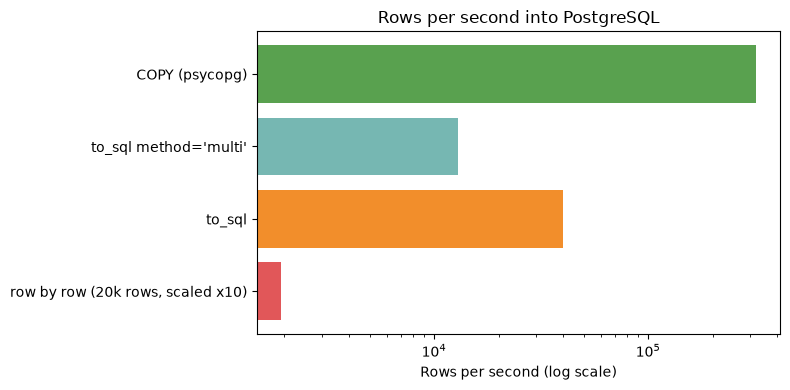

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(load_times), [200_000 / t for t in load_times.values()], color=["#E15759", "#F28E2B", "#76B7B2", "#59A14F"])
ax.set(xscale="log", title="Rows per second into PostgreSQL", xlabel="Rows per second (log scale)")
plt.tight_layout()
plt.show()

`COPY` streams all rows through one command and is one to two orders of magnitude faster than one `INSERT` per row. `method="multi"` was slower than the default `to_sql` here: with psycopg 3, the default already sends rows in efficient batches, while very long multi-row `INSERT` statements cost extra time to build and parse. Always measure with your own driver and data. (The row-by-row method was measured on 20,000 rows and scaled up, to keep the notebook fast.)

*Insight: Always pass values as parameters, never with f-strings. Wrap related writes in one transaction, read large results in chunks, and load bulk data with `COPY` (or your database's bulk loader), not with row-by-row inserts.*

## Real-World Use Case or Analogy

A connection pool is like a **taxi rank**: taxis (connections) wait ready, and each passenger (query) takes one instead of buying a new car. `COPY` is a **lorry** instead of 200,000 bicycle trips. A parameterised query is a **form with fixed fields**: whatever a customer writes in the "name" field stays a name; it cannot change the form.

SQL injection has caused some of the largest data breaches in history, and it is still in the OWASP Top 10 list of web risks. Every web framework and database driver supports parameters precisely to prevent it.